## Load & Import

In [7]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

In [8]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"
description_file = current_dir / "HomeCredit_columns_description.xlsx"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


In [9]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

## Column descriptions
Read the supplied Excel data dictionary to understand each column before preprocessing.

In [ ]:
column_descriptions = pd.read_excel(description_file, engine="openpyxl")

# Show every row and the complete descriptions.
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(column_descriptions)

,Row,Description
0,SK_ID_CURR,ID of loan in our sample
1,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)"
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving
3,CODE_GENDER,Gender of the client
4,CNT_CHILDREN,Number of children the client has
5,AMT_INCOME_TOTAL,Income of the client
6,AMT_CREDIT,Credit amount of the loan
7,AMT_ANNUITY,Loan annuity
8,AMT_GOODS_PRICE,For consumer loans it is the price of the goods for which the loan is given
9,NAME_INCOME_TYPE,"Clients income type (businessman, working, maternity leave,)"


In [ ]:
from IPython.display import Markdown

# Classify by meaning, rather than relying only on the stored pandas dtype.
feature_groups = {
    "Categorical — nominal": [
        "NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
        "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE",
    ],
    "Categorical — binary": ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE"],
    "Categorical — ordinal": ["NAME_EDUCATION_TYPE", "REGION_RATING_CLIENT"],
    "Continuous numeric": [
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
        "REGION_POPULATION_RELATIVE", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    ],
    "Discrete numeric — counts": [
        "CNT_CHILDREN", "CNT_FAM_MEMBERS", "AMT_REQ_CREDIT_BUREAU_HOUR",
        "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",
    ],
    "Time / age measurements": [
        "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
        "OWN_CAR_AGE", "DAYS_LAST_PHONE_CHANGE",
    ],
    "Identifier": ["SK_ID_CURR"],
    "Target — binary categorical": ["TARGET"],
}
group_notes = {
    "Categorical — nominal": "Category labels without an inherent ranking.",
    "Categorical — binary": "Yes/no indicators stored as 0 or 1. They are categorical even though their dtype is integer.",
    "Categorical — ordinal": "Education levels and region rating levels (1, 2, 3) have meaningful order. Education is stored as text; an ordinal encoding requires an explicit ordering of its levels.",
    "Continuous numeric": "Amounts, proportions, and scores, usually analyzed as continuous measurements.",
    "Discrete numeric — counts": "Numbers of people or credit enquiries. A float dtype does not turn a count into a continuous measurement.",
    "Time / age measurements": "Numeric ages or durations recorded in days, except OWN_CAR_AGE, which is in years. These are separate from event counts; date offsets and sentinel values need interpretation before preprocessing.",
    "Identifier": "A customer/loan key for matching rows; not a measurement of the customer.",
    "Target — binary categorical": "The outcome to predict: 0 = no default, 1 = default. Kept separate from the input features.",
}

# Verify that every training column appears once, with no omissions.
classified_columns = [column for columns in feature_groups.values() for column in columns]
assert len(classified_columns) == len(set(classified_columns)), "A column appears in multiple groups."
assert set(classified_columns) == set(train.columns), "Update the grouping to cover every training column."

feature_types = pd.DataFrame([
    {
        "Column": column,
        "Feature type": group,
        "Stored dtype": str(train[column].dtype),
        "Non-missing unique values": train[column].nunique(dropna=True),
    }
    for group, columns in feature_groups.items()
    for column in columns
])

display(Markdown("### Features grouped by data type\nSemantic type and stored dtype are different. The groups below cover all training columns."))
for group, columns in feature_groups.items():
    display(Markdown(f"#### {group} ({len(columns)} columns)\n{group_notes[group]}"))
    display(feature_types.loc[
        feature_types["Feature type"].eq(group),
        ["Column", "Stored dtype", "Non-missing unique values"],
    ].reset_index(drop=True))


### Features grouped by data type
Semantic type and stored dtype are different. The groups below cover all training columns.

#### Categorical — nominal (7 columns)
Category labels without an inherent ranking.

,Column,Stored dtype,Non-missing unique values
0,NAME_CONTRACT_TYPE,str,2
1,CODE_GENDER,str,3
2,NAME_INCOME_TYPE,str,8
3,NAME_FAMILY_STATUS,str,6
4,NAME_HOUSING_TYPE,str,6
5,OCCUPATION_TYPE,str,19
6,ORGANIZATION_TYPE,str,58


#### Categorical — binary (3 columns)
Yes/no indicators stored as 0 or 1. They are categorical even though their dtype is integer.

,Column,Stored dtype,Non-missing unique values
0,FLAG_MOBIL,int64,2
1,FLAG_EMP_PHONE,int64,2
2,FLAG_WORK_PHONE,int64,2


#### Categorical — ordinal (2 columns)
Education levels and region rating levels (1, 2, 3) have meaningful order. Education is stored as text; an ordinal encoding requires an explicit ordering of its levels.

... (7 outputs left out)

#### Identifier (1 columns)
A customer/loan key for matching rows; not a measurement of the customer.

,Column,Stored dtype,Non-missing unique values
0,SK_ID_CURR,int64,171202


#### Target — binary categorical (1 columns)
The outcome to predict: 0 = no default, 1 = default. Kept separate from the input features.

,Column,Stored dtype,Non-missing unique values
0,TARGET,int64,2


## Dataset Inspection

In [10]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [11]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


In [ ]:
# Check missing values of train data
train.isnull().sum()

In [ ]:
# Check missing values of test data
test.isnull().sum()

## Target class imbalance
Compare the number and percentage of customers with `TARGET = 0` (no default) and `TARGET = 1` (default) in the training data. Percentages use customers with a non-missing target; missing targets are reported separately. A large difference between these classes indicates imbalance.

,Count,Percentage (%)
TARGET,,
No default (0),157381,91.93
Default (1),13821,8.07


Missing TARGET values: 0
No-default to default ratio: 11.39:1


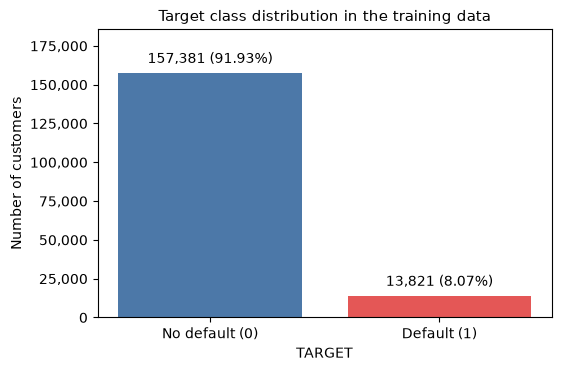

In [ ]:
# Count both target classes and check for missing labels.
target_missing = train["TARGET"].isna().sum()
target_counts = train["TARGET"].value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_counts / target_counts.sum() * 100,
})
target_summary.index = pd.Index(["No default (0)", "Default (1)"], name="TARGET")
display(target_summary.round(2))
print(f"Missing TARGET values: {target_missing:,}")

if target_counts.loc[1] > 0:
    imbalance_ratio = target_counts.loc[0] / target_counts.loc[1]
    print(f"No-default to default ratio: {imbalance_ratio:.2f}:1")
else:
    print("No default examples found; a class ratio cannot be calculated.")

fig, ax = plt.subplots(figsize=(5.5, 3.6), layout="constrained")
bars = ax.bar(target_summary.index, target_summary["Count"], color=["#4C78A8", "#E45756"])
labels = [
    f"{count:,} ({percentage:.2f}%)"
    for count, percentage in zip(target_summary["Count"], target_summary["Percentage (%)"])
]
ax.bar_label(bars, labels=labels, padding=5)
ax.set_title("Target class distribution in the training data", fontsize=11)
ax.set_xlabel("TARGET")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, target_summary["Count"].max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
plt.show()
plt.close(fig)


## Contract type and target counts
The 2×2 contingency table counts training customers by contract type and target: `TARGET = 0` means no payment difficulties (no default), and `TARGET = 1` means payment difficulties (default). Each table and heatmap entry is a customer count. `TARGET` is absent from the test data, so its test missing-value count is not applicable.

In [ ]:
# Missing values in the two variables used for the contingency table.
contract_missing = pd.DataFrame({
    "Train missing": train[["NAME_CONTRACT_TYPE", "TARGET"]].isna().sum(),
    "Test missing": test[["NAME_CONTRACT_TYPE"]].isna().sum(),
}).astype("Int64")
display(contract_missing)

,Train missing,Test missing
NAME_CONTRACT_TYPE,0,0
TARGET,0,<NA>


TARGET,No default (0),Default (1)
Contract type,,
Cash loans,142067,12921
Revolving loans,15314,900


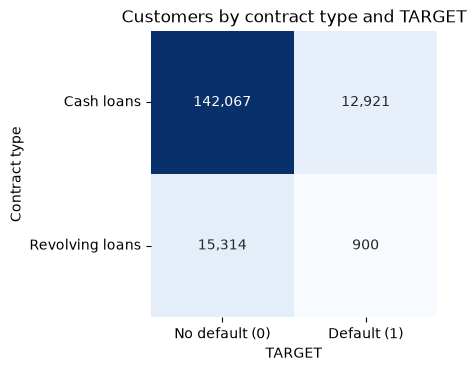

In [ ]:
# Count customers for every contract-type / target combination.
contract_counts = pd.crosstab(
    train["NAME_CONTRACT_TYPE"], train["TARGET"],
    rownames=["Contract type"], colnames=["TARGET"],
).rename(columns={0: "No default (0)", 1: "Default (1)"})
display(contract_counts)

fig, ax = plt.subplots(figsize=(4.8, 3.6), layout="constrained")
sns.heatmap(
    contract_counts, annot=True, fmt=",d", cmap="Blues",
    square=True, cbar=False, ax=ax,
)
ax.set_title("Customers by contract type and TARGET")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.show()
plt.close(fig)

## Default percentages within each contract type
Divide each count by the total customers for that contract type and multiply by 100. Each bar totals 100%, so the default proportions can be compared even though the contract types have different numbers of customers.

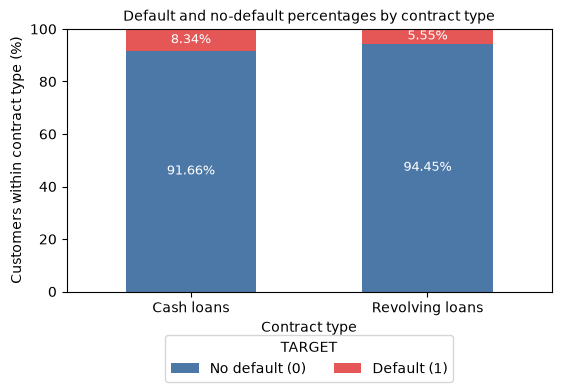

In [ ]:
# Normalize within each contract type (each row sums to 100%).
contract_percentages = contract_counts.div(contract_counts.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(5.5, 3.8), layout="constrained")
contract_percentages.plot.bar(
    stacked=True, color=["#4C78A8", "#E45756"], width=0.55, ax=ax,
)

# Label both the no-default and default segments with their percentages.
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", label_type="center", color="white", fontsize=9)

ax.set_title("Default and no-default percentages by contract type", fontsize=10)
ax.set_xlabel("Contract type")
ax.set_ylabel("Customers within contract type (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="TARGET", loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
plt.show()
plt.close(fig)


## Contract type percentages after random undersampling
Keep all default customers and randomly select the same number of no-default customers without replacement. This balances `TARGET` across the dataset, not separately within each contract type. The original `train` stays unchanged. These graphs demonstrate how resampling changes the observed proportions; they do not represent the original default rates. For model training, split first and resample only the training portion, leaving validation and test data unchanged.

,Count
TARGET,
0,13821
1,13821


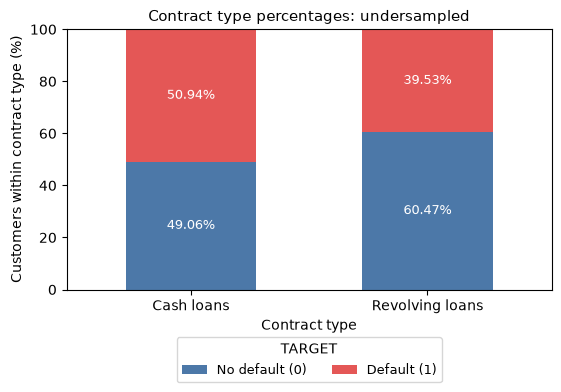

In [ ]:
# Balance TARGET by reducing the majority class, without duplicate rows.
no_default = train.loc[train["TARGET"] == 0]
default = train.loc[train["TARGET"] == 1]
train_undersampled = pd.concat([
    no_default.sample(n=len(default), replace=False, random_state=42),
    default,
]).sample(frac=1, random_state=42).reset_index(drop=True)

# Verify overall class balance, then normalize within each contract type.
undersampled_target_counts = train_undersampled["TARGET"].value_counts().sort_index()
display(undersampled_target_counts.rename("Count").to_frame())
undersampled_contract_counts = pd.crosstab(
    train_undersampled["NAME_CONTRACT_TYPE"], train_undersampled["TARGET"],
    rownames=["Contract type"], colnames=["TARGET"],
).reindex(columns=[0, 1], fill_value=0).rename(
    columns={0: "No default (0)", 1: "Default (1)"},
)
undersampled_contract_percentages = undersampled_contract_counts.div(
    undersampled_contract_counts.sum(axis=1), axis=0,
) * 100

fig, ax = plt.subplots(figsize=(5.5, 3.8), layout="constrained")
undersampled_contract_percentages.plot.bar(
    stacked=True, color=["#4C78A8", "#E45756"], width=0.55, ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Contract type percentages: undersampled", fontsize=11)
ax.set_xlabel("Contract type")
ax.set_ylabel("Customers within contract type (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="TARGET", loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
plt.show()
plt.close(fig)


## Contract type percentages after random oversampling
Keep every original customer and add randomly selected copies of default customers until both target classes have the same size. Sampling with replacement creates duplicate rows; it does not create new information. Balance is overall, so each contract type can still have a different default percentage.

,Count
TARGET,
0,157381
1,157381


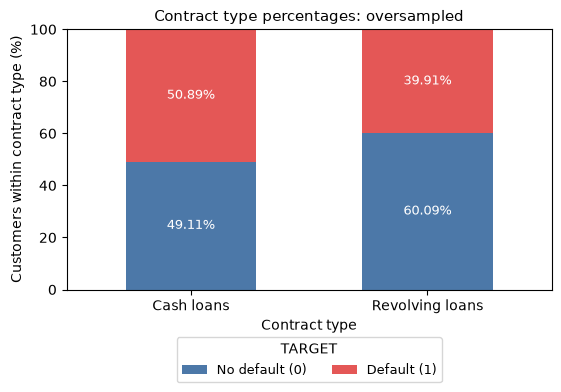

In [ ]:
# Balance TARGET by adding copies of minority-class rows.
no_default = train.loc[train["TARGET"] == 0]
default = train.loc[train["TARGET"] == 1]
extra_defaults = default.sample(
    n=len(no_default) - len(default), replace=True, random_state=42,
)
train_oversampled = pd.concat([
    no_default, default, extra_defaults,
]).sample(frac=1, random_state=42).reset_index(drop=True)

# Verify overall class balance, then normalize within each contract type.
oversampled_target_counts = train_oversampled["TARGET"].value_counts().sort_index()
display(oversampled_target_counts.rename("Count").to_frame())
oversampled_contract_counts = pd.crosstab(
    train_oversampled["NAME_CONTRACT_TYPE"], train_oversampled["TARGET"],
    rownames=["Contract type"], colnames=["TARGET"],
).reindex(columns=[0, 1], fill_value=0).rename(
    columns={0: "No default (0)", 1: "Default (1)"},
)
oversampled_contract_percentages = oversampled_contract_counts.div(
    oversampled_contract_counts.sum(axis=1), axis=0,
) * 100

fig, ax = plt.subplots(figsize=(5.5, 3.8), layout="constrained")
oversampled_contract_percentages.plot.bar(
    stacked=True, color=["#4C78A8", "#E45756"], width=0.55, ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Contract type percentages: oversampled", fontsize=11)
ax.set_xlabel("Contract type")
ax.set_ylabel("Customers within contract type (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="TARGET", loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
plt.show()
plt.close(fig)


## All categorical features: undersampling and oversampling
The following two figures show no-default and default percentages **within each category**. Include the text columns, the three binary phone flags, and the ordinal region rating; numeric amounts, durations, and counts are not categorical features. Each observed category totals 100%. Each subplot is sorted by **default percentage, highest first**, with absent categories last. Beside each bar, the two columns show **percentage (sampled count)** for no default and default. Ties retain the original frequency order. Category order can differ between the two resampled datasets. A category absent after sampling is marked **No sampled rows**, rather than assigned a misleading 0% rate. Missing values, if present, get their own category.

These are the same balanced exploration copies used above. Counts refer to rows in each resampled dataset; oversampled counts include duplicate customers, and percentages for rare categories can be unstable. For model evaluation, resample only the training portion after splitting.

In [ ]:
import textwrap
from matplotlib.patches import Patch

# Include categorical values that happen to be stored as integers.
text_features = train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
encoded_categories = ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "REGION_RATING_CLIENT"]
categorical_features = list(dict.fromkeys(text_features + encoded_categories))
categorical_features = [column for column in categorical_features if column != "TARGET"]

# Keep every original category; use original frequency order to break percentage ties.
category_orders = {
    column: train[column].astype("string").fillna("<Missing>").value_counts().index.tolist()
    for column in categorical_features
}

def plot_categorical_target_percentages(data, sampling_name):
    """Return one figure and count/percentage tables for every categorical feature."""
    summaries = {}
    for column in categorical_features:
        categories = data[column].astype("string").fillna("<Missing>")
        counts = pd.crosstab(categories, data["TARGET"]).reindex(
            index=category_orders[column], columns=[0, 1], fill_value=0,
        )
        totals = counts.sum(axis=1)
        percentages = counts.div(totals.replace(0, np.nan), axis=0) * 100
        summaries[column] = pd.DataFrame({
            "No default count": counts[0],
            "Default count": counts[1],
            "Total sampled rows": totals,
            "No default (%)": percentages[0],
            "Default (%)": percentages[1],
        }).sort_values("Default (%)", ascending=False, na_position="last", kind="stable")

    # Assign more space to features with many categories and balance column heights.
    panel_heights = {
        column: max(2.7, 1.2 + 0.34 * len(category_orders[column]))
        for column in categorical_features
    }
    panel_columns = [[], []]
    column_heights = [0.0, 0.0]
    for column in sorted(categorical_features, key=panel_heights.get, reverse=True):
        destination = int(np.argmin(column_heights))
        panel_columns[destination].append(column)
        column_heights[destination] += panel_heights[column]

    figure_height = max(column_heights) + 1.4
    fig = plt.figure(figsize=(24, figure_height), layout="constrained")
    fig.set_constrained_layout_pads(w_pad=0.2, h_pad=0.15, wspace=0.08, hspace=0.03)
    outer_grid = fig.add_gridspec(1, 2)
    for column_index, features in enumerate(panel_columns):
        panels = outer_grid[0, column_index].subgridspec(
            len(features), 1, height_ratios=[panel_heights[column] for column in features],
        )
        for panel_index, column in enumerate(features):
            ax = fig.add_subplot(panels[panel_index, 0])
            summary = summaries[column]
            y_positions = np.arange(len(summary))
            no_default = summary["No default (%)"].fillna(0).to_numpy()
            default = summary["Default (%)"].fillna(0).to_numpy()
            ax.barh(y_positions, no_default, color="#4C78A8", height=0.7)
            ax.barh(y_positions, default, left=no_default, color="#E45756", height=0.7)

            # Show each class's percentage and its actual sampled row count.
            for row_index, row in enumerate(summary.itertuples(index=False, name=None)):
                no_count, default_count, total, no_pct, default_pct = row
                no_label = f"{no_pct:5.1f}% ({no_count:,})" if total else "— (0)"
                default_label = f"{default_pct:5.1f}% ({default_count:,})" if total else "— (0)"
                ax.text(104, row_index, no_label, va="center", fontsize=10,
                        fontfamily="monospace", color="#333333")
                ax.text(166, row_index, default_label, va="center", fontsize=10,
                        fontfamily="monospace", color="#333333")
                if not total:
                    ax.text(50, row_index, "No sampled rows", ha="center", va="center",
                            fontsize=10, color="#666666")

            category_labels = [textwrap.fill(str(category), width=26) for category in summary.index]
            if column.startswith("FLAG_"):
                category_labels = [{"0": "0 — No", "1": "1 — Yes"}.get(label, label)
                                   for label in category_labels]
            ax.set_yticks(y_positions, labels=category_labels, fontsize=10)
            ax.set_ylim(len(summary) - 0.5, -0.5)
            ax.set_xlim(0, 225)
            ax.set_xticks([0, 25, 50, 75, 100])
            ax.tick_params(axis="x", labelsize=10)
            ax.set_xlabel("Customers within category (%)", fontsize=10)
            ax.set_title(column, loc="left", fontsize=13, fontweight="bold", pad=24)
            ax.text(104, 1.015, "No default: % (count)", transform=ax.get_xaxis_transform(),
                    fontsize=10, va="bottom")
            ax.text(166, 1.015, "Default: % (count)", transform=ax.get_xaxis_transform(),
                    fontsize=10, va="bottom")
            ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        f"All categorical features — {sampling_name}\n"
        f"{len(data):,} sampled rows • sorted by default percentage (highest first) • counts include sampled copies",
        fontsize=17,
    )
    fig.legend(handles=[Patch(color="#4C78A8", label="No default (0)"),
                        Patch(color="#E45756", label="Default (1)")],
               loc="outside lower center", ncol=2, fontsize=12, frameon=False)
    return fig, summaries


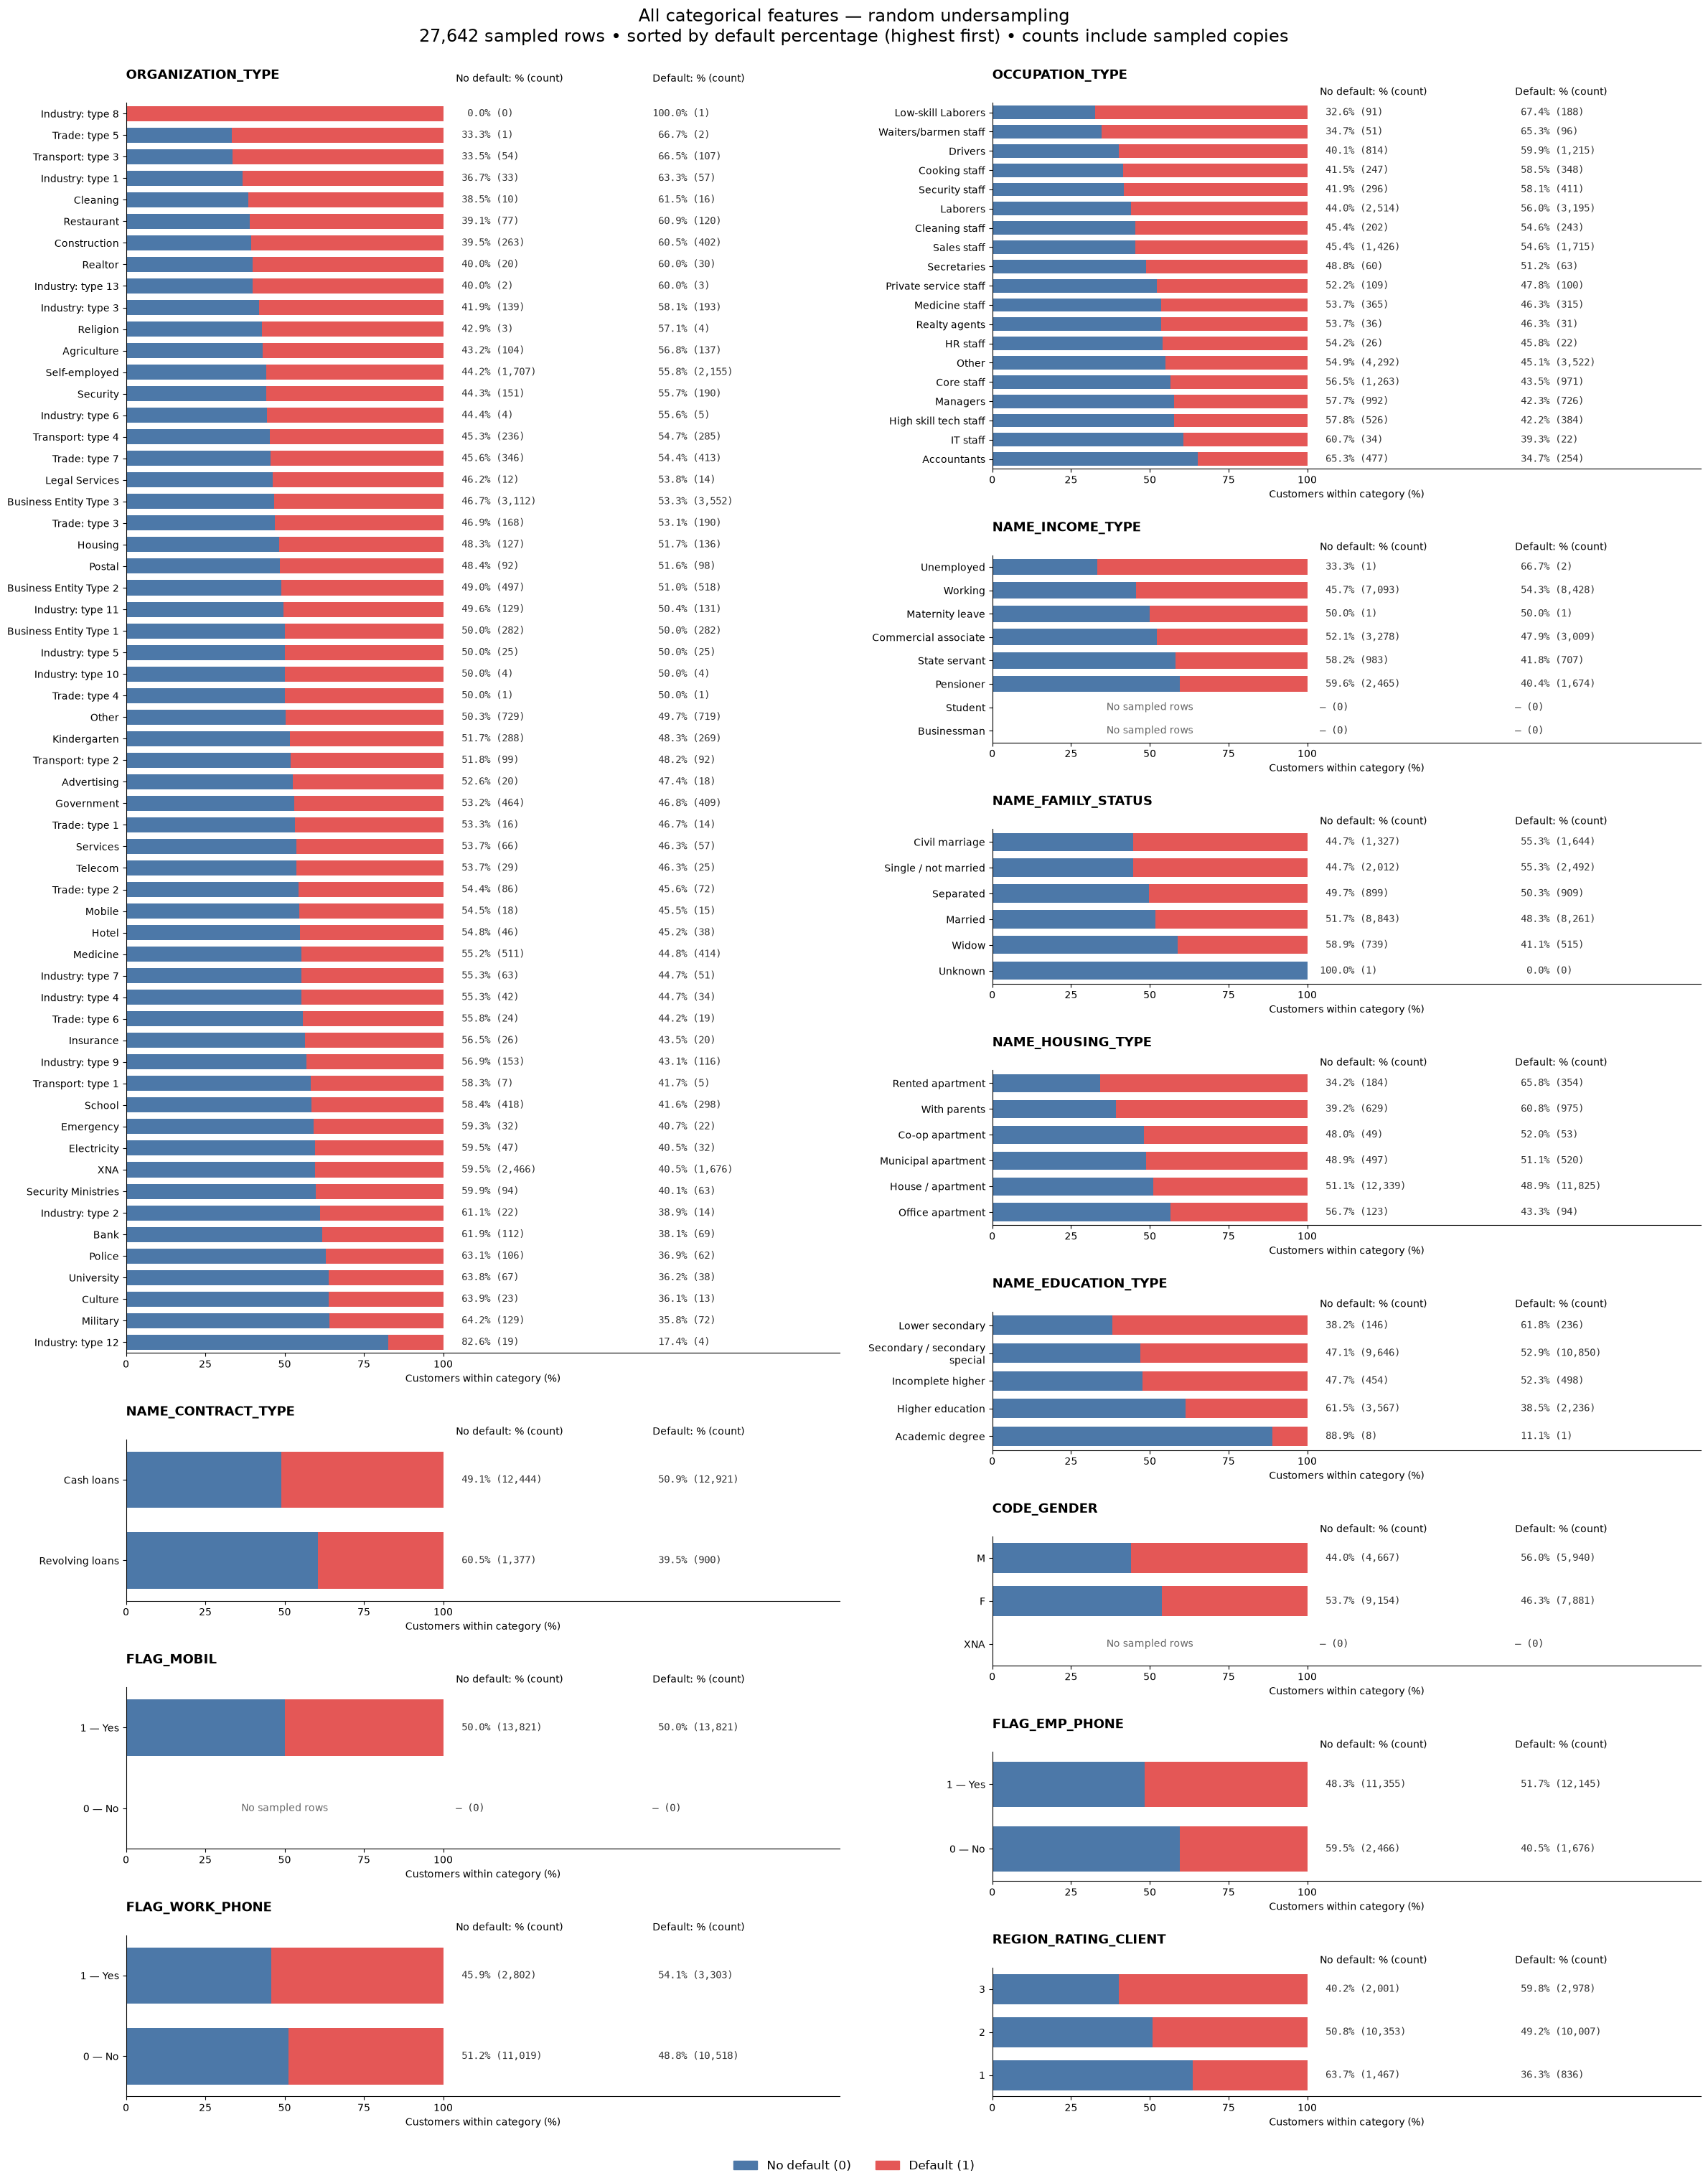

In [ ]:
# Use the undersampled dataset created above (13,821 rows per class).
fig, undersampled_categorical_summary = plot_categorical_target_percentages(
    train_undersampled, "random undersampling",
)
plt.show()
plt.close(fig)


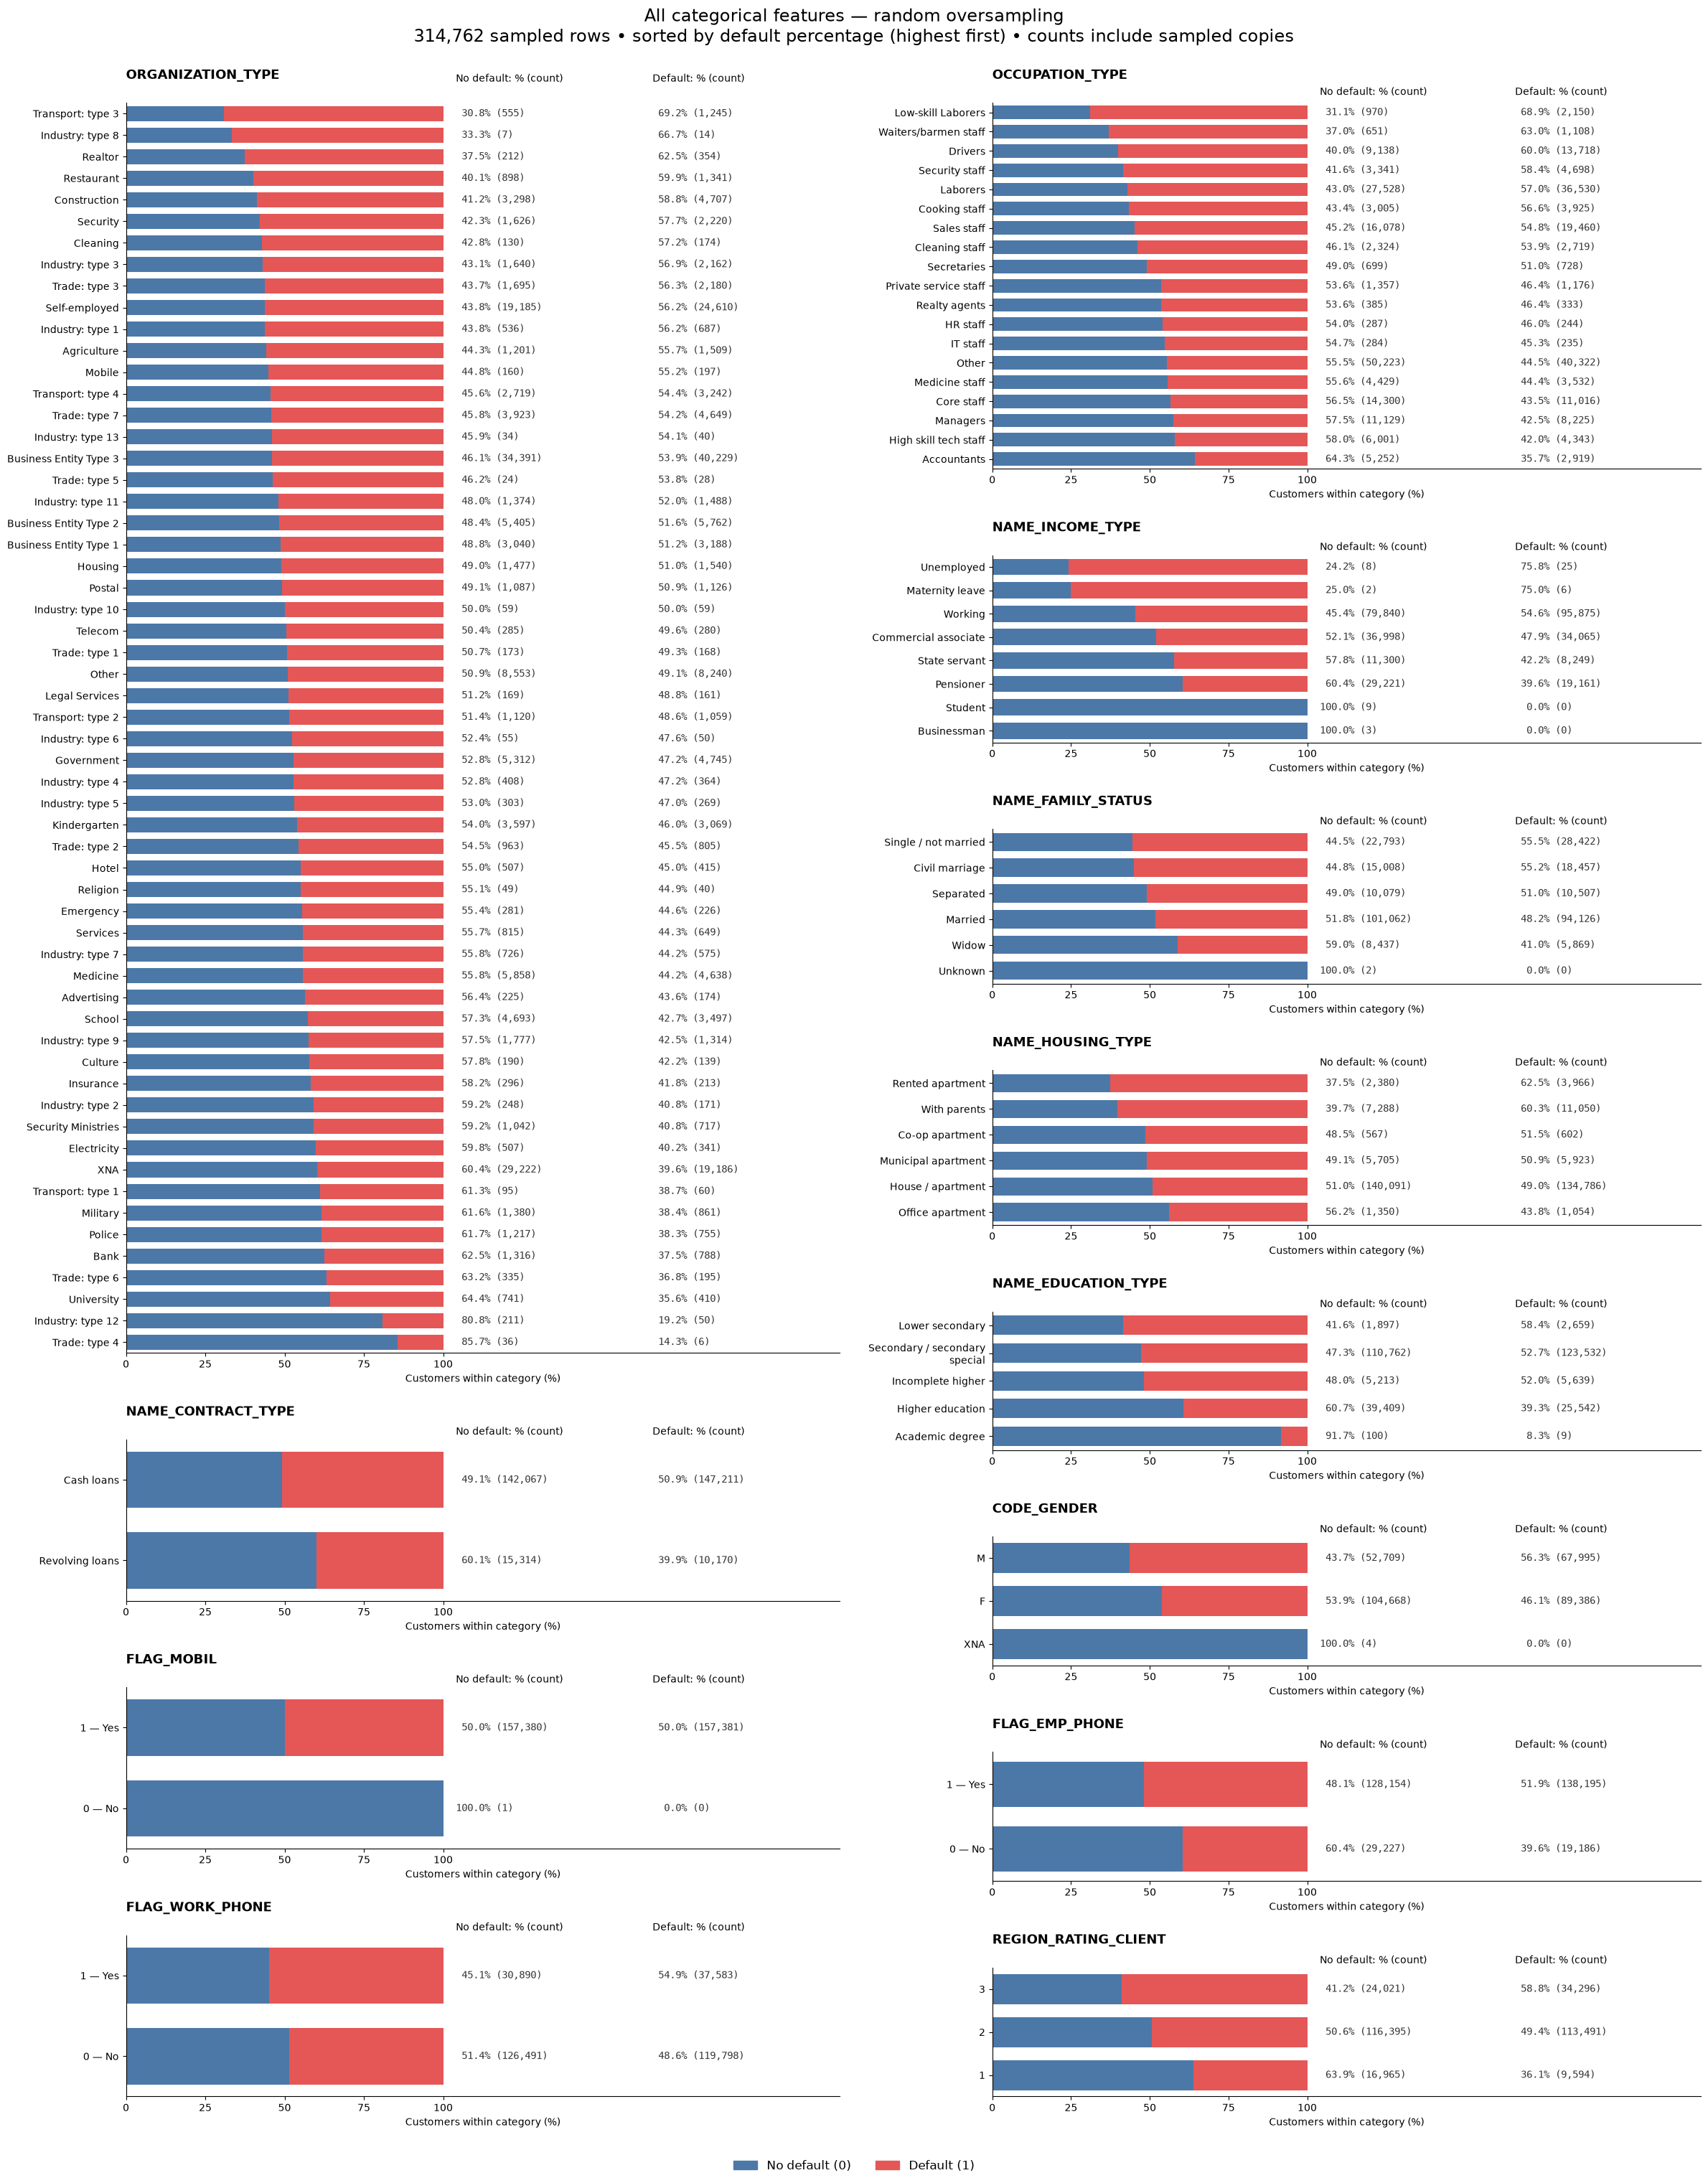

In [ ]:
# Use the oversampled dataset created above (157,381 rows per class).
fig, oversampled_categorical_summary = plot_categorical_target_percentages(
    train_oversampled, "random oversampling",
)
plt.show()
plt.close(fig)
